# 01 — Simple Linear Regression

> Fitting a straight line through data to predict a continuous value.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. The data
5. Modeling
6. Results and interpretation
7. References

## 1. The problem

Every car sold has a fuel consumption rating and a CO2 emissions figure. I want
to predict the **CO2 emissions** of a car from a single property of it — its
**engine size**.

- **Input:** engine size, in litres (one number per car)
- **Output:** CO2 emissions, in grams per kilometre (one number per car)
- **A good answer** is a rule that, given an engine size I have never seen
  before, produces an emissions estimate close to the truth.

This is *simple* linear regression: simple because there is exactly one input
feature, linear because the rule I am allowed to learn is a straight line.

## 2. Intuition

Plot every car as a dot: engine size across, emissions up. The dots do not fall
in a random cloud — bigger engines sit higher. A straight line drawn through the
middle of that cloud captures the pattern.

There are infinitely many lines I could draw. To pick one, I need to say what
makes a line *good*. The answer used here: a good line is the one whose vertical
distances to the dots are small. Take each of those distances, square it so that
being wrong above and wrong below both count as wrong, and add them all up. The
best line is the one that makes that sum as small as possible.

Section 3 is that sentence written in symbols.

## 3. The mathematics

**Model.** With one feature $x$ (engine size), the prediction is a line:

$$
\hat{y} = w x + b
$$

where $w$ is the slope — how many grams of CO2 per extra litre of engine — and
$b$ is the intercept, the value the line takes at $x = 0$.

**Cost function.** For $m$ training cars, the quantity to be minimised is the
mean squared error, the *residual sum of squares* averaged over the data:

$$
J(w, b) = \frac{1}{m} \sum_{i=1}^{m} \left( \hat{y}^{(i)} - y^{(i)} \right)^2
        = \frac{1}{m} \sum_{i=1}^{m} \left( w x^{(i)} + b - y^{(i)} \right)^2
$$

Squaring is what makes an error above the line and an error below it count the
same, and what makes one large miss cost more than several small ones.

**Finding the parameters.** $J$ is a quadratic function of $w$ and $b$, so it
has a single minimum and no local traps. Setting its derivatives to zero gives a
system that can be solved directly — no search required. That closed-form
solution is what `LinearRegression.fit()` computes, which is why fitting is
instant here and why the answer is exact rather than approximate.

Notice what this implies: every training row must be available at once for the
parameters to be calculated.

## 4. The data

`FuelConsumption.csv` — fuel consumption ratings and CO2 emissions for new light
duty vehicles sold in Canada in 2014, published as open data by the Government
of Canada.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Fixed seed so the train/test split is identical every run. Without this, the
# coefficients and scores reported below change each time the notebook executes.
RANDOM_SEED = 42

In [2]:
df = pd.read_csv("data/FuelConsumption.csv")

# take a look at the dataset
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [3]:
# summarize the data
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


The file carries 13 columns, but most are identifiers (make, model, transmission
type) rather than measurements. I keep the four numeric columns that plausibly
relate to emissions.

In [4]:
cdf = df[["ENGINESIZE", "CYLINDERS", "FUELCONSUMPTION_COMB", "CO2EMISSIONS"]]
cdf.head(9)

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,8.5,196
1,2.4,4,9.6,221
2,1.5,4,5.9,136
3,3.5,6,11.1,255
4,3.5,6,10.6,244
5,3.5,6,10.0,230
6,3.5,6,10.1,232
7,3.7,6,11.1,255
8,3.7,6,11.6,267


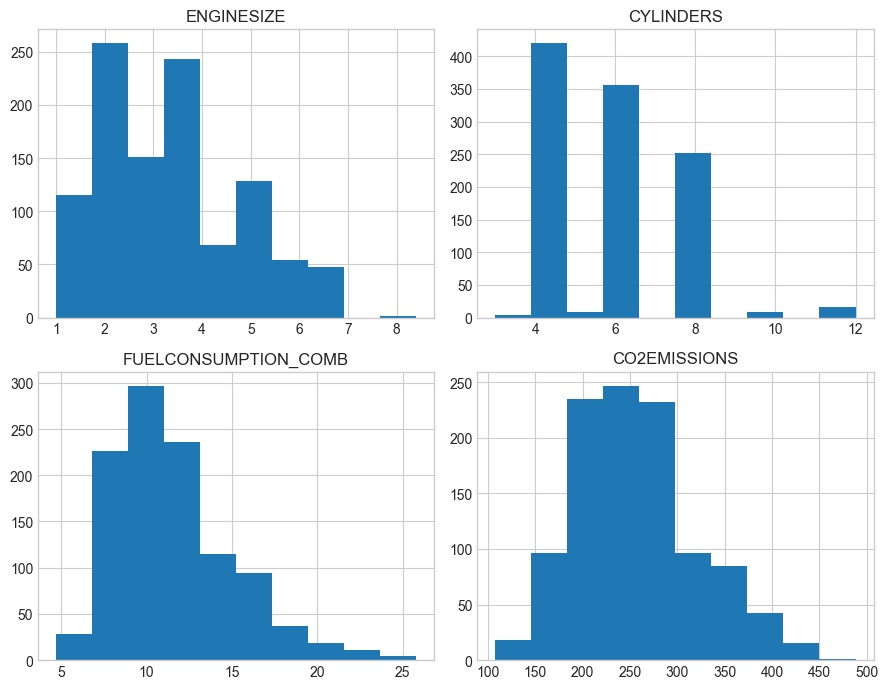

In [5]:
cdf.hist(figsize=(9, 7))
plt.tight_layout()
plt.show()

Engine size and cylinder count are clumped at a few common values — engines come
in standard sizes, and no car has 5.5 cylinders. Emissions are more continuous
and roughly bell shaped, with a tail of heavy vehicles.

Next, which of these features actually predicts emissions?

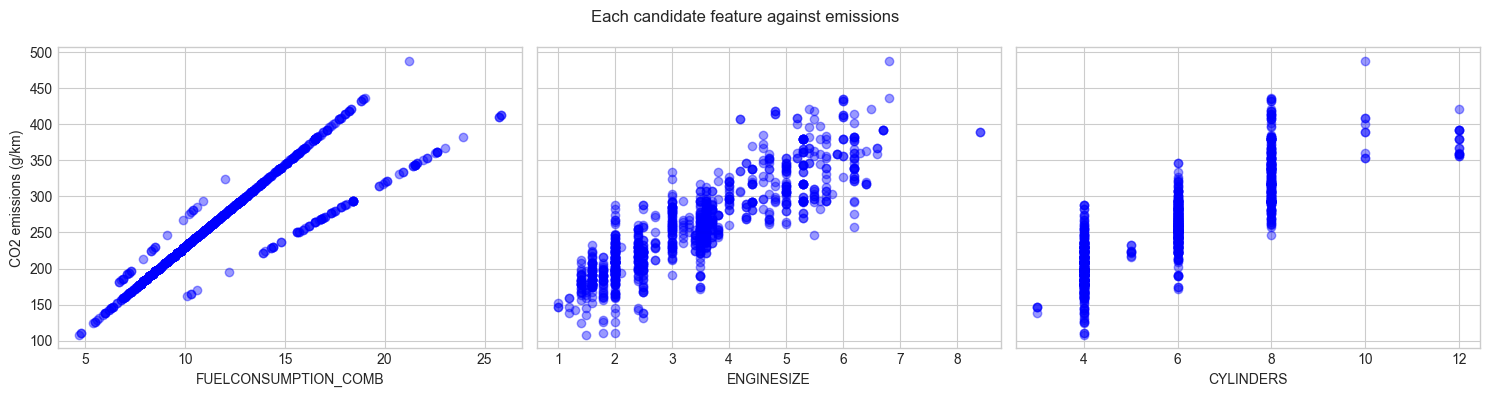

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, column in zip(axes, ["FUELCONSUMPTION_COMB", "ENGINESIZE", "CYLINDERS"]):
    ax.scatter(cdf[column], cdf["CO2EMISSIONS"], color="blue", alpha=0.4)
    ax.set_xlabel(column)

axes[0].set_ylabel("CO2 emissions (g/km)")
fig.suptitle("Each candidate feature against emissions")
plt.tight_layout()
plt.show()

All three trend upward, which is what physical sense predicts: a bigger engine
burns more fuel, and burning more fuel emits more CO2.

Fuel consumption is the tightest relationship — unsurprisingly, since emissions
are close to a direct chemical consequence of fuel burned. Cylinders form
vertical stripes because the feature only takes a handful of integer values.

**I use engine size.** It is a genuine predictor with visible spread around the
trend, which makes it a more honest test of the method than fuel consumption,
where the line would be almost trivially good.

### Creating train and test datasets

The model is fitted on one portion of the data and evaluated on another it has
never seen. Scoring a model on the same rows it learned from measures memory,
not prediction — it would happily report a good score for a model that has
learned nothing general.

I use the common 80/20 division.

In [7]:
# Going toward the common approach of 80% / 20% (80 for training, 20 for testing)
rng = np.random.default_rng(RANDOM_SEED)
msk = rng.random(len(cdf)) < 0.8

train = cdf[msk]
test = cdf[~msk]

print(f"training rows: {len(train)}")
print(f"test rows:     {len(test)}")

training rows: 859
test rows:     208


#### Train and test distribution

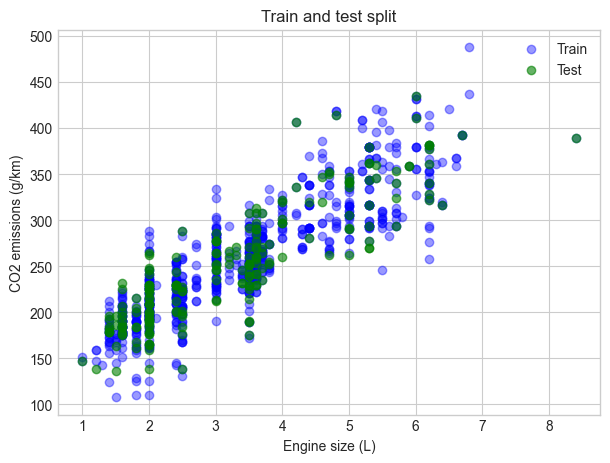

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(train.ENGINESIZE, train.CO2EMISSIONS, color="blue", alpha=0.4, label="Train")
ax.scatter(test.ENGINESIZE, test.CO2EMISSIONS, color="green", alpha=0.6, label="Test")
ax.set_xlabel("Engine size (L)")
ax.set_ylabel("CO2 emissions (g/km)")
ax.set_title("Train and test split")
ax.legend()
plt.show()

The green points are spread through the same region as the blue ones rather than
concentrated in one corner, so the test set is a fair sample of the problem and
not a harder or easier slice of it.

## 5. Modeling

Using the scikit-learn package to fit the line described in section 3.

In [9]:
from sklearn import linear_model

train_x = train[["ENGINESIZE"]].to_numpy()
train_y = train["CO2EMISSIONS"].to_numpy()

reg = linear_model.LinearRegression()

# fit means we tell our model to find the best line; afterwards we can read off
# the coefficient and the intercept it settled on.
reg.fit(train_x, train_y)

print("Coefficients: ", reg.coef_)
print("Intercept:    ", reg.intercept_)

Coefficients:  [39.28980209]
Intercept:     124.9416047709642


**Coefficient** and **intercept** are the two parameters of the fitted line —
its slope and where it crosses the vertical axis. Because the model has only
these two, and because the cost has a closed-form minimum, scikit-learn
estimates them directly from the data rather than searching for them.

Reading the slope: each additional litre of engine displacement is associated
with roughly 39 more grams of CO2 per kilometre.

The intercept has no physical meaning. There is no 0-litre car; the number is
simply where the line happens to cross the axis, far outside the range of
anything in the data.

## 6. Results and interpretation

### Plotting the fitted line

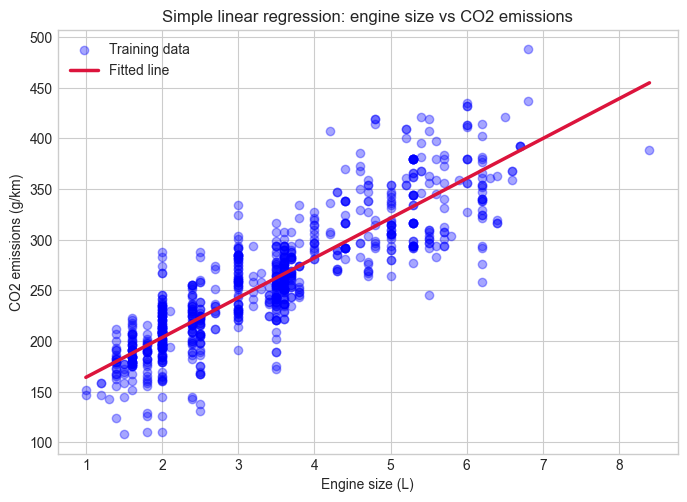

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))

ax.scatter(
    train.ENGINESIZE, train.CO2EMISSIONS, color="blue", alpha=0.35, label="Training data"
)

# Draw the line from the fitted parameters, using the equation y = b + w * x
line_x = np.linspace(train_x.min(), train_x.max(), 100)
ax.plot(
    line_x,
    reg.intercept_ + reg.coef_[0] * line_x,
    color="crimson",
    linewidth=2.5,
    label="Fitted line",
)

ax.set_xlabel("Engine size (L)")
ax.set_ylabel("CO2 emissions (g/km)")
ax.set_title("Simple linear regression: engine size vs CO2 emissions")
ax.legend()

# Saved so README.md can show the result without anyone running this notebook.
fig.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

### Evaluation

Comparing predicted values against actual ones is what turns a fitted line into
a measured one. Each metric answers a different question:

- **MAE** (mean absolute error) — the average size of a miss, in grams per km.
  The easiest to read, because it is in the same units as the target.
- **MSE** (mean squared error) — the average squared miss. More common than MAE
  because squaring makes large errors dominate, and large errors are usually
  what matter. It is also the quantity the fitting procedure itself minimised.
- **RMSE** — the square root of MSE, which puts the number back into grams per
  km so it can be compared with MAE.
- **R²** — not an error but a score: the fraction of the variation in emissions
  the line accounts for. 1.0 is perfect, 0 means the line is no better than
  always guessing the mean, and it can go negative for a model worse than that.

All of them are computed on the **test** set, which the model has never seen.

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_x = test[["ENGINESIZE"]].to_numpy()
test_y = test["CO2EMISSIONS"].to_numpy()

# For each test car, predict the emissions its engine size implies — so for a
# 4.2 litre engine, what CO2 figure does the fitted line expect?
test_y_ = reg.predict(test_x)

print(f"Mean absolute error:             {mean_absolute_error(test_y, test_y_):.2f} g/km")
print(f"Residual sum of squares (MSE):   {mean_squared_error(test_y, test_y_):.2f}")
print(f"Root mean squared error (RMSE):  {np.sqrt(mean_squared_error(test_y, test_y_)):.2f} g/km")
print(f"R2-score:                        {r2_score(test_y, test_y_):.2f}")

Mean absolute error:             24.43 g/km
Residual sum of squares (MSE):   993.50
Root mean squared error (RMSE):  31.52 g/km
R2-score:                        0.76


**Reading the result.** An R² of 0.76 means engine size alone explains about
three quarters of the variation in emissions — a lot for a single feature, and
far from everything. The typical miss is roughly 24 g/km.

Where the line fails is visible in the plot. At any given engine size the real
cars spread across a band tens of grams wide, because emissions also depend on
vehicle weight, transmission, and fuel type. A line through one feature cannot
express that, and averages over it instead.

The remaining quarter of the variation is not noise — it is structure this model
has no vocabulary for. Adding those features is exactly what multiple linear
regression does, which is the next lesson.

## 7. References

- Course: Machine Learning with Python (Jadi) — lesson on simple linear
  regression, which uses this dataset and framing.
- Dataset: [Fuel consumption ratings, Government of Canada open data](https://open.canada.ca/data/en/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64)
- scikit-learn documentation: [Ordinary least squares](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares)